In [1]:
import sys
import os
sys.path.append(os.path.abspath('../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.subsampling import *

from sklearn import set_config
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import make_scorer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sksurv.metrics import integrated_brier_score
from sksurv.metrics import concordance_index_ipcw
from sksurv.nonparametric import kaplan_meier_estimator
from sklearn.inspection import permutation_importance
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from sksurv.metrics import concordance_index_censored
from sksurv.util import Surv
from sksurv.linear_model import CoxnetSurvivalAnalysis, CoxPHSurvivalAnalysis

import time
set_config(display="text")  # displays text representation of estimators

In [2]:
dataset = pd.read_csv("../data/final/data_final.csv")

diagnosis_variables = []

with open("../data/final/diagnosis_final.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("../data/final/treatment_final.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

survival_dataset = dataset.drop('Unnamed: 0', axis=1)

feature_columns = treatment_variables + diagnosis_variables

In [3]:
# Find duplicated patients with regional ln recurrence = 1
mask = (survival_dataset.duplicated(subset='PERSON_ID', keep=False)) #& (survival_dataset['Regional LN recurrence'] == 1)

# For each duplicated PERSON_ID with recurrence, keep only the row with the lowest survival days
to_remove = (
    survival_dataset[mask]
    .sort_values(['PERSON_ID', 'Survival days'], ascending=[True, True])
    .groupby('PERSON_ID')
    .head(-1)
    .index
)

survival_dataset = survival_dataset.drop(to_remove)

In [4]:
# Prepare data
data_x = survival_dataset[feature_columns]

data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'],
    time=survival_dataset['Survival days']
)
# Since every duplicated patient has a consistent event indicator (regional ln recurrence) I can use this method
groups = survival_dataset['PERSON_ID']

In [5]:
sgkf = StratifiedKFold(n_splits=5, shuffle=True, random_state=12)
cv = sgkf.split(X=data_x, y=survival_dataset['Regional LN recurrence'])

train_index, test_index = next(cv)

In [6]:
for train_idx, val_idx in cv:
    print("Train events:", survival_dataset.iloc[train_idx]["Regional LN recurrence"].sum())
    print("Val events:", survival_dataset.iloc[val_idx]["Regional LN recurrence"].sum())

Train events: 27.0
Val events: 6.0
Train events: 26.0
Val events: 7.0
Train events: 26.0
Val events: 7.0
Train events: 26.0
Val events: 7.0


In [7]:
print("Train events:", survival_dataset.iloc[train_index]["Regional LN recurrence"].sum())
print("Test events:", survival_dataset.iloc[test_index]["Regional LN recurrence"].sum())

Train events: 27.0
Test events: 6.0


In [8]:
subsampling = survival_dataset.iloc[train_index].copy()

x_train = data_x.iloc[train_index]
y_train = data_y[train_index]

x_test = data_x.iloc[test_index]
y_test = data_y[test_index]
sgkf_1 = StratifiedKFold(n_splits=4, shuffle=True, random_state=12)

In [9]:
l1_ratio = 1
model = CoxnetSurvivalAnalysis(l1_ratio=l1_ratio)
alphas = np.logspace(-3.5, -2, 20)
(alphas)
list_alphas = alphas.tolist()
alphas = pd.DataFrame(list_alphas, columns=['Alphas'])

In [13]:
# Define your hyperparameter ranges

alpha_range = np.logspace(-3, 0, 10)  # 20 alpha values
l1_ratio_range = [1.0, 0.8, 0.5, 0.01, 0.001]  # From Lasso to Ridge
controls_per_case_range = [5, 10, 15]  # Different subsampling ratios

# Include deviance alongside other metrics
metrics = ['c-index', 'c-index-ipcw', 'int-brier-score', 'deviance']

# Run grid search
results, best_params, summary_df = subsampling_grid_search(
    dataset=survival_dataset,
    X=x_train,
    y=y_train,
    cv_folds=sgkf_1,
    alpha_range=alpha_range,
    l1_ratio_range=l1_ratio_range,
    controls_per_case_range=controls_per_case_range,
    metrics=metrics,
    feature_columns=feature_columns,
    scaler=StandardScaler(),
    verbose=True
)

SUBSAMPLING GRID SEARCH
Controls per case: [5, 10, 15]
L1 ratios: [1.0, 0.8, 0.5, 0.01, 0.001]
Alphas: 10 values from 1.00e-03 to 1.00e+00
Total combinations: 150

[1/150] controls=5, l1=1.000, alpha=1.00e-03 (elapsed: 0.0min, est. remaining: 0.0min)
⚠️  Info: 5 constant features detected with StandardScaler.
   Removing these features to avoid NaN values (StandardScaler divides by std=0).
   Constant feature indices: [ 1 32 33 38 47]
   Features after removal: 43 (removed 5)


c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\linear_model\coxph.py:125: RuntimeWarning: overflow encountered in exp
  risk_score = np.exp(linear_predictor)


  ⚠️ Configuration failed: Input estimate contains NaN.
[2/150] controls=5, l1=1.000, alpha=2.15e-03 (elapsed: 0.1min, est. remaining: 6.9min)
⚠️  Info: 5 constant features detected with StandardScaler.
   Removing these features to avoid NaN values (StandardScaler divides by std=0).
   Constant feature indices: [ 1 32 33 38 47]
   Features after removal: 43 (removed 5)
⚠️  Info: 3 constant features detected with StandardScaler.
   Removing these features to avoid NaN values (StandardScaler divides by std=0).
   Constant feature indices: [32 38 47]
   Features after removal: 45 (removed 3)


c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\linear_model\coxph.py:125: RuntimeWarning: overflow encountered in exp
  risk_score = np.exp(linear_predictor)


  ⚠️ Configuration failed: Input estimate contains NaN.
[3/150] controls=5, l1=1.000, alpha=4.64e-03 (elapsed: 0.2min, est. remaining: 8.6min)
⚠️  Info: 5 constant features detected with StandardScaler.
   Removing these features to avoid NaN values (StandardScaler divides by std=0).
   Constant feature indices: [ 1 32 33 38 47]
   Features after removal: 43 (removed 5)
⚠️  Info: 3 constant features detected with StandardScaler.
   Removing these features to avoid NaN values (StandardScaler divides by std=0).
   Constant feature indices: [32 38 47]
   Features after removal: 45 (removed 3)


c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\linear_model\coxph.py:125: RuntimeWarning: overflow encountered in exp
  risk_score = np.exp(linear_predictor)


... (5 outputs left out)

c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\linear_model\coxph.py:125: RuntimeWarning: overflow encountered in exp
  risk_score = np.exp(linear_predictor)


  ⚠️ Configuration failed: Input estimate contains NaN.
[102/150] controls=15, l1=1.000, alpha=2.15e-03 (elapsed: 5.3min, est. remaining: 2.5min)
⚠️  Info: 2 constant features detected with StandardScaler.
   Removing these features to avoid NaN values (StandardScaler divides by std=0).
   Constant feature indices: [33 47]
   Features after removal: 46 (removed 2)


c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\linear_model\coxph.py:125: RuntimeWarning: overflow encountered in exp
  risk_score = np.exp(linear_predictor)


  ⚠️ Configuration failed: Input estimate contains NaN.
[103/150] controls=15, l1=1.000, alpha=4.64e-03 (elapsed: 5.4min, est. remaining: 2.5min)
⚠️  Info: 2 constant features detected with StandardScaler.
   Removing these features to avoid NaN values (StandardScaler divides by std=0).
   Constant feature indices: [33 47]
   Features after removal: 46 (removed 2)
⚠️  Info: 2 constant features detected with StandardScaler.
   Removing these features to avoid NaN values (StandardScaler divides by std=0).
   Constant feature indices: [33 47]
   Features after removal: 46 (removed 2)
⚠️  Info: 2 constant features detected with StandardScaler.
   Removing these features to avoid NaN values (StandardScaler divides by std=0).
   Constant feature indices: [33 47]
   Features after removal: 46 (removed 2)
[104/150] controls=15, l1=1.000, alpha=1.00e-02 (elapsed: 5.5min, est. remaining: 2.4min)
⚠️  Info: 2 constant features detected with StandardScaler.
   Removing these features to avoid NaN v

In [11]:
# Extract best parameters for each metric from grid search
# EXCLUDE configurations that had ANY failed folds (NaN values in c-index or c-index-ipcw)
# Note: We don't care about brier score failures

# First, identify configurations where ANY fold has NaN values in c-index or c-index-ipcw
configs_with_nan_folds = set()

for n_controls in results.keys():
    for l1_ratio in results[n_controls].keys():
        for alpha in results[n_controls][l1_ratio].keys():
            results_df = results[n_controls][l1_ratio][alpha]
            
            # Check if any fold has NaN in c-index or c-index-ipcw (ignore brier scores)
            fold_rows = results_df.loc[results_df.index.str.startswith('Fold_')]
            
            # Only check c-index and c-index-ipcw columns
            critical_metrics = ['c-index', 'c-index-ipcw']
            if fold_rows[critical_metrics].isna().any().any():
                configs_with_nan_folds.add((n_controls, l1_ratio, alpha))

print(f"Configurations with at least one failed fold: {len(configs_with_nan_folds)}")

# Filter summary_df to exclude configurations with ANY failed folds
def is_valid_config(row):
    return (row['n_controls'], row['l1_ratio'], row['alpha']) not in configs_with_nan_folds

valid_summary_df = summary_df[summary_df.apply(is_valid_config, axis=1)].copy()

print(f"Total configurations: {len(summary_df)}")
print(f"Valid configurations (all folds successful): {len(valid_summary_df)}")
print(f"Excluded configurations (had failed folds): {len(summary_df) - len(valid_summary_df)}")

best_params = {}
for metric in ['c-index', 'c-index-ipcw', 'brier_2yr', 'brier_5yr', 'brier_10yr']:
    metric_df = valid_summary_df[valid_summary_df['metric'] == metric]
    
    if len(metric_df) == 0:
        print(f"\n⚠️  WARNING: No valid configurations for {metric}!")
        continue
    
    # For Brier scores, lower is better
    if metric.startswith('brier'):
        best_idx = metric_df['mean'].idxmin()
    else:
        best_idx = metric_df['mean'].idxmax()
    
    best_row = metric_df.loc[best_idx]
    
    best_params[metric] = {
        'n_controls': best_row['n_controls'],
        'l1_ratio': best_row['l1_ratio'],
        'alpha': best_row['alpha'],
        'mean': best_row['mean'],
        'std': best_row['std']
    }

# Access best parameters
print("\n" + "="*80)
print("BEST PARAMETERS FROM GRID SEARCH (only fully successful configurations)")
print("="*80)
for metric, params in best_params.items():
    print(f"\n{metric.upper()}:")
    print(f"  n_controls_per_case: {params['n_controls']}")
    print(f"  l1_ratio: {params['l1_ratio']:.4f}")
    print(f"  alpha: {params['alpha']:.4e}")
    print(f"  Score: {params['mean']:.4f} ± {params['std']:.4f}")

print("\n" + "="*80)
print("CHECKING FOR CONFIGURATIONS WITH FAILED FOLDS")
print("="*80)

# Show which unique configurations had failures
print(f"\nUnique configurations with failed folds: {len(configs_with_nan_folds)}")
if len(configs_with_nan_folds) > 0:
    print("\nConfigurations excluded from best parameter selection:")
    for n_controls, l1_ratio, alpha in sorted(configs_with_nan_folds):
        print(f"  n_controls={n_controls}, l1_ratio={l1_ratio:.3f}, alpha={alpha:.2e}")

# Also check if any specific results DataFrames have NaN in individual folds
print("\n" + "="*80)
print("DETAILED FOLD-LEVEL CHECK FOR BEST PARAMETERS")
print("="*80)

for metric, params in best_params.items():
    n_controls = params['n_controls']
    l1_ratio = params['l1_ratio']
    alpha = params['alpha']
    
    print(f"\n{metric.upper()} - Best Config (n_controls={n_controls}, l1={l1_ratio:.3f}, α={alpha:.2e}):")
    
    # Get the specific results DataFrame
    results_df = results[n_controls][l1_ratio][alpha]
    
    # Check for NaN in individual folds
    fold_rows = results_df.loc[results_df.index.str.startswith('Fold_')]
    nan_folds = fold_rows[fold_rows[metric].isna()]
    
    if len(nan_folds) > 0:
        print(f"  ❌ {len(nan_folds)} fold(s) returned NaN:")
        for fold_name in nan_folds.index:
            print(f"     {fold_name}")
    else:
        print(f"  ✅ All {len(fold_rows)} folds completed successfully")
        print(f"     Fold scores: {fold_rows[metric].values}")

print("\n" + "="*80)

Configurations with at least one failed fold: 24
Total configurations: 240
Valid configurations (all folds successful): 144
Excluded configurations (had failed folds): 96

⚠️  WARNING: No valid configurations for brier_2yr!

⚠️  WARNING: No valid configurations for brier_5yr!

⚠️  WARNING: No valid configurations for brier_10yr!

BEST PARAMETERS FROM GRID SEARCH (only fully successful configurations)

C-INDEX:
  n_controls_per_case: 10
  l1_ratio: 0.8000
  alpha: 5.9948e-03
  Score: 0.9105 ± 0.0541

C-INDEX-IPCW:
  n_controls_per_case: 10
  l1_ratio: 0.5000
  alpha: 5.9948e-03
  Score: 0.8510 ± 0.1052

CHECKING FOR CONFIGURATIONS WITH FAILED FOLDS

Unique configurations with failed folds: 24

Configurations excluded from best parameter selection:
  n_controls=10, l1_ratio=0.500, alpha=1.00e-04
  n_controls=10, l1_ratio=0.500, alpha=2.78e-04
  n_controls=10, l1_ratio=0.500, alpha=7.74e-04
  n_controls=10, l1_ratio=0.500, alpha=2.15e-03
  n_controls=10, l1_ratio=0.800, alpha=1.00e-04
  n

In [12]:
# Find best c-index-ipcw hyperparameters with lowest standard deviation
print("="*80)
print("BEST C-INDEX-IPCW HYPERPARAMETERS WITH LOWEST STD")
print("="*80)

# Filter for c-index-ipcw metric only and valid configurations
# Also exclude configurations where mean is exactly 0.5
ipcw_valid = valid_summary_df[valid_summary_df['metric'] == 'c-index-ipcw'].copy()
ipcw_valid = ipcw_valid[ipcw_valid['mean'] != 0.5]

if len(ipcw_valid) > 0:
    # Find configuration with minimum std
    min_std_idx = ipcw_valid['std'].idxmin()
    min_std_config = ipcw_valid.loc[min_std_idx]
    
    print(f"\nConfiguration with LOWEST standard deviation:")
    print(f"  n_controls_per_case: {int(min_std_config['n_controls'])}")
    print(f"  l1_ratio: {min_std_config['l1_ratio']:.4f}")
    print(f"  alpha: {min_std_config['alpha']:.4e}")
    print(f"  Mean: {min_std_config['mean']:.4f}")
    print(f"  Std:  {min_std_config['std']:.4f}")
    
    # Compare with best mean performance
    best_mean_idx = ipcw_valid['mean'].idxmax()
    best_mean_config = ipcw_valid.loc[best_mean_idx]
    
    print(f"\n" + "-"*80)
    print("COMPARISON: Lowest Std vs Highest Mean")
    print("-"*80)
    
    print(f"\nLowest Std configuration:")
    print(f"  n_controls={int(min_std_config['n_controls'])}, l1_ratio={min_std_config['l1_ratio']:.4f}, alpha={min_std_config['alpha']:.4e}")
    print(f"  Mean: {min_std_config['mean']:.4f}, Std: {min_std_config['std']:.4f}")
    
    print(f"\nHighest Mean configuration:")
    print(f"  n_controls={int(best_mean_config['n_controls'])}, l1_ratio={best_mean_config['l1_ratio']:.4f}, alpha={best_mean_config['alpha']:.4e}")
    print(f"  Mean: {best_mean_config['mean']:.4f}, Std: {best_mean_config['std']:.4f}")
    
    print(f"\nDifferences:")
    print(f"  Mean difference: {min_std_config['mean'] - best_mean_config['mean']:.4f}")
    print(f"  Std difference: {min_std_config['std'] - best_mean_config['std']:.4f}")
    
    # Get detailed fold-level results for lowest std config
    n_controls_min = int(min_std_config['n_controls'])
    l1_ratio_min = min_std_config['l1_ratio']
    alpha_min = min_std_config['alpha']
    
    print(f"\n" + "-"*80)
    print("DETAILED FOLD-LEVEL RESULTS FOR LOWEST STD CONFIGURATION")
    print("-"*80)
    
    results_df_min = results[n_controls_min][l1_ratio_min][alpha_min]
    fold_rows_min = results_df_min.loc[results_df_min.index.str.startswith('Fold_')]
    
    print(f"\nIndividual fold scores for c-index-ipcw:")
    for fold_name in fold_rows_min.index:
        fold_score = fold_rows_min.loc[fold_name, 'c-index-ipcw']
        if pd.isna(fold_score):
            print(f"  {fold_name}: NaN (failed)")
        else:
            print(f"  {fold_name}: {fold_score:.4f}")
    
    print(f"\nMean: {results_df_min.loc['Mean', 'c-index-ipcw']:.4f}")
    print(f"Std:  {results_df_min.loc['Std', 'c-index-ipcw']:.4f}")
    
    # Show other metrics for this configuration
    print(f"\nOther metrics for lowest std configuration:")
    print(f"  c-index: {results_df_min.loc['Mean', 'c-index']:.4f} ± {results_df_min.loc['Std', 'c-index']:.4f}")
    print(f"  int-brier-score: {results_df_min.loc['Mean', 'int-brier-score']:.4f} ± {results_df_min.loc['Std', 'int-brier-score']:.4f}")
    
else:
    print("\n⚠️  No valid c-index-ipcw configurations found!")

print("\n" + "="*80)

BEST C-INDEX-IPCW HYPERPARAMETERS WITH LOWEST STD

Configuration with LOWEST standard deviation:
  n_controls_per_case: 10
  l1_ratio: 0.5000
  alpha: 1.2915e-01
  Mean: 0.6899
  Std:  0.0394

--------------------------------------------------------------------------------
COMPARISON: Lowest Std vs Highest Mean
--------------------------------------------------------------------------------

Lowest Std configuration:
  n_controls=10, l1_ratio=0.5000, alpha=1.2915e-01
  Mean: 0.6899, Std: 0.0394

Highest Mean configuration:
  n_controls=10, l1_ratio=0.5000, alpha=5.9948e-03
  Mean: 0.8510, Std: 0.1052

Differences:
  Mean difference: -0.1610
  Std difference: -0.0658

--------------------------------------------------------------------------------
DETAILED FOLD-LEVEL RESULTS FOR LOWEST STD CONFIGURATION
--------------------------------------------------------------------------------

Individual fold scores for c-index-ipcw:
  Fold_1: 0.6383
  Fold_2: 0.7338
  Fold_3: 0.6906
  Fold_4: 0.

In [13]:
# Show c-index results when using the best hyperparameters from c-index-ipcw
print("="*80)
print("C-INDEX RESULTS USING BEST C-INDEX-IPCW HYPERPARAMETERS")
print("="*80)

if 'c-index-ipcw' in best_params:
    ipcw_params = best_params['c-index-ipcw']
    n_controls = ipcw_params['n_controls']
    l1_ratio = ipcw_params['l1_ratio']
    alpha = ipcw_params['alpha']
    
    print(f"\nBest c-index-ipcw hyperparameters:")
    print(f"  n_controls_per_case: {n_controls}")
    print(f"  l1_ratio: {l1_ratio:.4f}")
    print(f"  alpha: {alpha:.4e}")
    
    # Get the results for this configuration
    results_df = results[n_controls][l1_ratio][alpha]
    
    # Extract c-index scores
    print(f"\nC-INDEX scores for this configuration:")
    print(f"  Mean: {results_df.loc['Mean', 'c-index']:.4f}")
    print(f"  Std:  {results_df.loc['Std', 'c-index']:.4f}")
    
    # Show individual fold scores
    fold_rows = results_df.loc[results_df.index.str.startswith('Fold_')]
    print(f"\n  Individual fold scores:")
    for fold_name in fold_rows.index:
        fold_score = fold_rows.loc[fold_name, 'c-index']
        if pd.isna(fold_score):
            print(f"    {fold_name}: NaN (failed)")
        else:
            print(f"    {fold_name}: {fold_score:.4f}")
    
    # Compare with best c-index configuration
    if 'c-index' in best_params:
        cindex_params = best_params['c-index']
        print(f"\n" + "-"*80)
        print("COMPARISON WITH BEST C-INDEX HYPERPARAMETERS:")
        print(f"\nBest c-index hyperparameters:")
        print(f"  n_controls_per_case: {cindex_params['n_controls']}")
        print(f"  l1_ratio: {cindex_params['l1_ratio']:.4f}")
        print(f"  alpha: {cindex_params['alpha']:.4e}")
        print(f"  Mean c-index: {cindex_params['mean']:.4f} ± {cindex_params['std']:.4f}")
        
        print(f"\nUsing c-index-ipcw hyperparameters:")
        print(f"  Mean c-index: {results_df.loc['Mean', 'c-index']:.4f} ± {results_df.loc['Std', 'c-index']:.4f}")
        
        diff = results_df.loc['Mean', 'c-index'] - cindex_params['mean']
        print(f"\nDifference: {diff:+.4f}")
else:
    print("\n⚠️  No valid c-index-ipcw configuration found!")

print("\n" + "="*80)

C-INDEX RESULTS USING BEST C-INDEX-IPCW HYPERPARAMETERS

Best c-index-ipcw hyperparameters:
  n_controls_per_case: 10
  l1_ratio: 0.5000
  alpha: 5.9948e-03

C-INDEX scores for this configuration:
  Mean: 0.9092
  Std:  0.0549

  Individual fold scores:
    Fold_1: 0.9017
    Fold_2: 0.9861
    Fold_3: 0.8561
    Fold_4: 0.8930

--------------------------------------------------------------------------------
COMPARISON WITH BEST C-INDEX HYPERPARAMETERS:

Best c-index hyperparameters:
  n_controls_per_case: 10
  l1_ratio: 0.8000
  alpha: 5.9948e-03
  Mean c-index: 0.9105 ± 0.0541

Using c-index-ipcw hyperparameters:
  Mean c-index: 0.9092 ± 0.0549

Difference: -0.0013



In [14]:
# Find best configuration using mean - std criterion (conservative estimate)
print("="*80)
print("BEST C-INDEX-IPCW CONFIGURATION USING (MEAN - STD) CRITERION")
print("="*80)
print("This criterion gives a conservative estimate of performance,")
print("favoring configurations that are both high-performing and stable.")
print("="*80)

# Filter for c-index-ipcw metric only and valid configurations
# Also exclude configurations where mean is exactly 0.5
ipcw_valid = valid_summary_df[valid_summary_df['metric'] == 'c-index-ipcw'].copy()
ipcw_valid = ipcw_valid[ipcw_valid['mean'] != 0.5]

if len(ipcw_valid) > 0:
    # Calculate conservative score: mean - std
    ipcw_valid['conservative_score'] = ipcw_valid['mean'] - ipcw_valid['std']
    
    # Find configuration with highest conservative score
    best_conservative_idx = ipcw_valid['conservative_score'].idxmax()
    best_conservative_config = ipcw_valid.loc[best_conservative_idx]
    
    print(f"\n" + "="*80)
    print("BEST CONFIGURATION BY CONSERVATIVE CRITERION (MEAN - STD)")
    print("="*80)
    
    n_controls_best = int(best_conservative_config['n_controls'])
    l1_ratio_best = best_conservative_config['l1_ratio']
    alpha_best = best_conservative_config['alpha']
    mean_best = best_conservative_config['mean']
    std_best = best_conservative_config['std']
    conservative_best = best_conservative_config['conservative_score']
    
    print(f"\nConfiguration:")
    print(f"  n_controls_per_case: {n_controls_best}")
    print(f"  l1_ratio: {l1_ratio_best:.4f}")
    print(f"  alpha: {alpha_best:.4e}")
    print(f"\nPerformance:")
    print(f"  C-Index IPCW Mean: {mean_best:.4f}")
    print(f"  C-Index IPCW Std:  {std_best:.4f}")
    print(f"  Conservative Score (Mean - Std): {conservative_best:.4f}")
    
    # Get full results for this configuration
    results_df_best = results[n_controls_best][l1_ratio_best][alpha_best]
    
    print(f"\n  C-Index: {results_df_best.loc['Mean', 'c-index']:.4f} ± {results_df_best.loc['Std', 'c-index']:.4f}")
    print(f"  Integrated Brier Score: {results_df_best.loc['Mean', 'int-brier-score']:.4f} ± {results_df_best.loc['Std', 'int-brier-score']:.4f}")
    
    # Show individual fold scores
    fold_rows_best = results_df_best.loc[results_df_best.index.str.startswith('Fold_')]
    print(f"\n  Individual fold scores:")
    print(f"    C-Index IPCW: {', '.join([f'{x:.4f}' for x in fold_rows_best['c-index-ipcw'].values])}")
    print(f"    C-Index:      {', '.join([f'{x:.4f}' for x in fold_rows_best['c-index'].values])}")
    
    # Compare with highest mean configuration
    print(f"\n" + "="*80)
    print("COMPARISON WITH HIGHEST MEAN CONFIGURATION")
    print("="*80)
    
    highest_mean_idx = ipcw_valid['mean'].idxmax()
    highest_mean_config = ipcw_valid.loc[highest_mean_idx]
    
    if best_conservative_idx == highest_mean_idx:
        print("\n✅ The conservative criterion selected the SAME configuration as highest mean!")
        print("   This configuration has both the highest mean AND good stability.")
    else:
        print(f"\nHighest Mean Configuration:")
        print(f"  n_controls={int(highest_mean_config['n_controls'])}, l1_ratio={highest_mean_config['l1_ratio']:.4f}, alpha={highest_mean_config['alpha']:.4e}")
        print(f"  Mean: {highest_mean_config['mean']:.4f}")
        print(f"  Std:  {highest_mean_config['std']:.4f}")
        print(f"  Conservative Score: {highest_mean_config['conservative_score']:.4f}")
        
        print(f"\nBest Conservative Configuration:")
        print(f"  n_controls={n_controls_best}, l1_ratio={l1_ratio_best:.4f}, alpha={alpha_best:.4e}")
        print(f"  Mean: {mean_best:.4f}")
        print(f"  Std:  {std_best:.4f}")
        print(f"  Conservative Score: {conservative_best:.4f}")
        
        print(f"\nTrade-off Analysis:")
        mean_loss = mean_best - highest_mean_config['mean']
        std_gain = highest_mean_config['std'] - std_best
        conservative_gain = conservative_best - highest_mean_config['conservative_score']
        
        print(f"  Mean loss:        {mean_loss:+.4f} (sacrificing peak performance)")
        print(f"  Std improvement:  {std_gain:+.4f} (gaining stability)")
        print(f"  Conservative gain: {conservative_gain:+.4f} (net improvement in worst-case)")
    
    # Show top 5 configurations by conservative score
    print(f"\n" + "="*80)
    print("TOP 5 CONFIGURATIONS BY CONSERVATIVE SCORE (MEAN - STD)")
    print("="*80)
    
    top_5_conservative = ipcw_valid.nlargest(5, 'conservative_score')
    
    print(f"\n{'Rank':<6} {'n_ctrl':<8} {'alpha':<12} {'Mean':<10} {'Std':<10} {'Mean-Std':<12} {'C-Index':<10}")
    print("-"*70)
    
    for rank, (idx, config) in enumerate(top_5_conservative.iterrows(), 1):
        n_c = int(config['n_controls'])
        alpha = config['alpha']
        mean = config['mean']
        std = config['std']
        cons_score = config['conservative_score']
        
        results_df = results[n_c][config['l1_ratio']][alpha]
        cindex = results_df.loc['Mean', 'c-index']
        
        print(f"{rank:<6} {n_c:<8} {alpha:<12.4e} {mean:<10.4f} {std:<10.4f} {cons_score:<12.4f} {cindex:<10.4f}")
    
else:
    print("\n⚠️  No valid c-index-ipcw configurations found!")

print("\n" + "="*80)

BEST C-INDEX-IPCW CONFIGURATION USING (MEAN - STD) CRITERION
This criterion gives a conservative estimate of performance,
favoring configurations that are both high-performing and stable.

BEST CONFIGURATION BY CONSERVATIVE CRITERION (MEAN - STD)

Configuration:
  n_controls_per_case: 15
  l1_ratio: 1.0000
  alpha: 5.9948e-03

Performance:
  C-Index IPCW Mean: 0.8442
  C-Index IPCW Std:  0.0817
  Conservative Score (Mean - Std): 0.7625

  C-Index: 0.9052 ± 0.0459
  Integrated Brier Score: 0.0124 ± 0.0022

  Individual fold scores:
    C-Index IPCW: 0.7684, 0.9545, 0.7994, 0.8545
    C-Index:      0.9338, 0.9540, 0.8741, 0.8587

COMPARISON WITH HIGHEST MEAN CONFIGURATION

Highest Mean Configuration:
  n_controls=10, l1_ratio=0.5000, alpha=5.9948e-03
  Mean: 0.8510
  Std:  0.1052
  Conservative Score: 0.7458

Best Conservative Configuration:
  n_controls=15, l1_ratio=1.0000, alpha=5.9948e-03
  Mean: 0.8442
  Std:  0.0817
  Conservative Score: 0.7625

Trade-off Analysis:
  Mean loss:     

{'n_controls': 10, 'l1_ratio': np.float64(0.8), 'alpha': np.float64(0.004641588833612777), 'mean': np.float64(0.8508113065878645), 'std': np.float64(0.1034181174668369)}


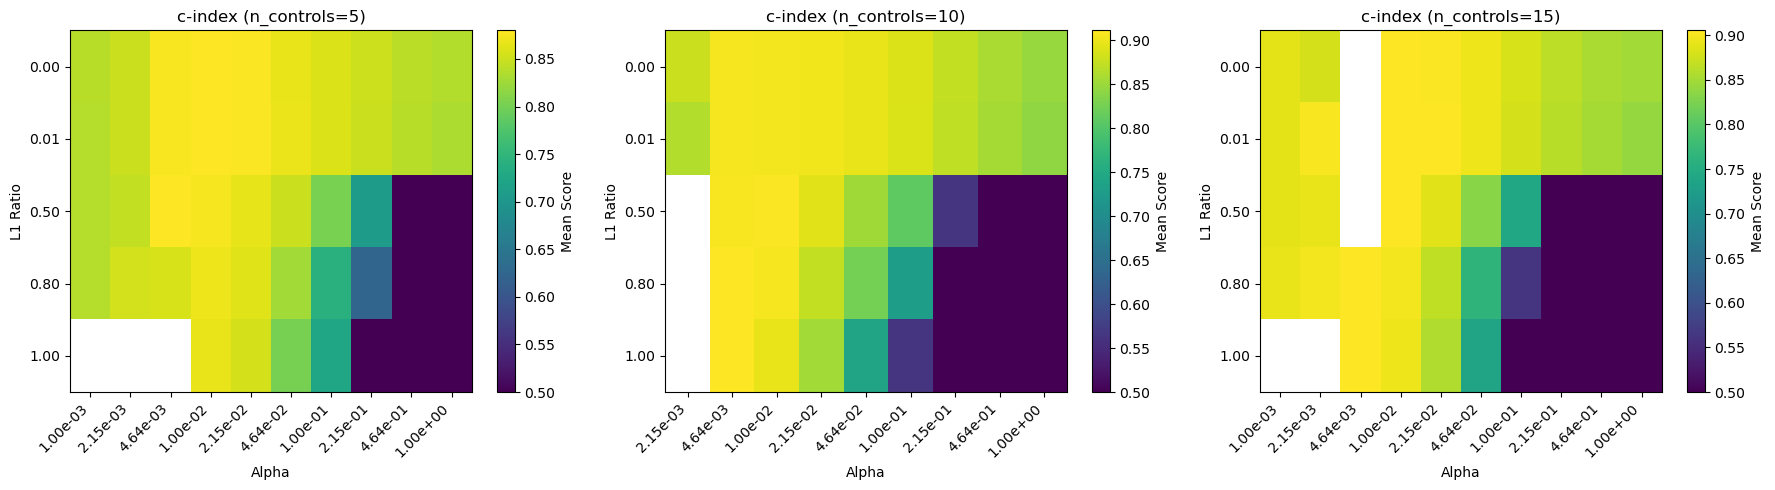

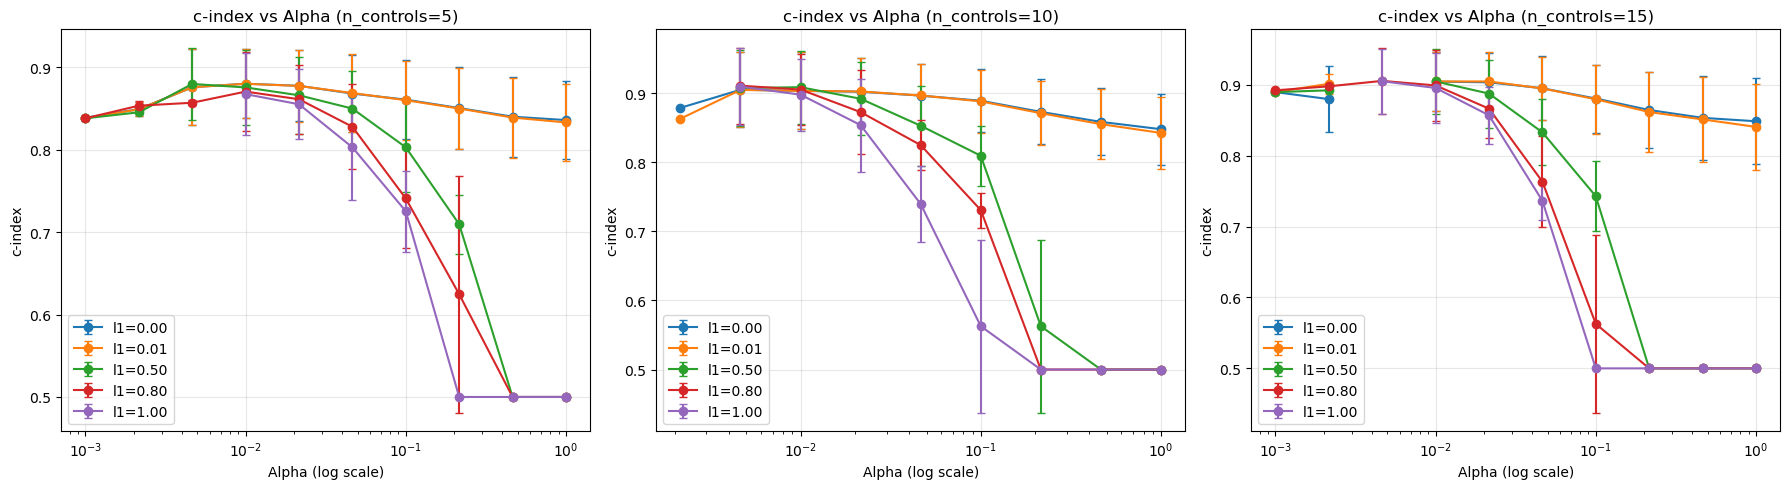

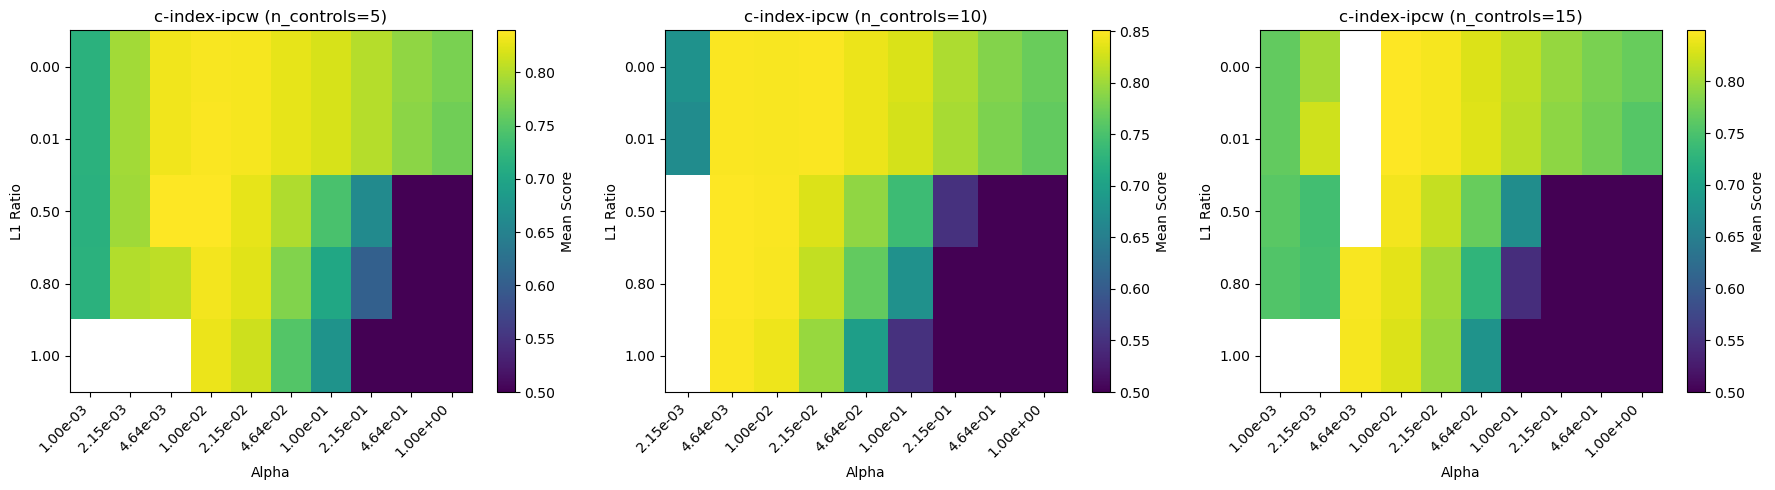

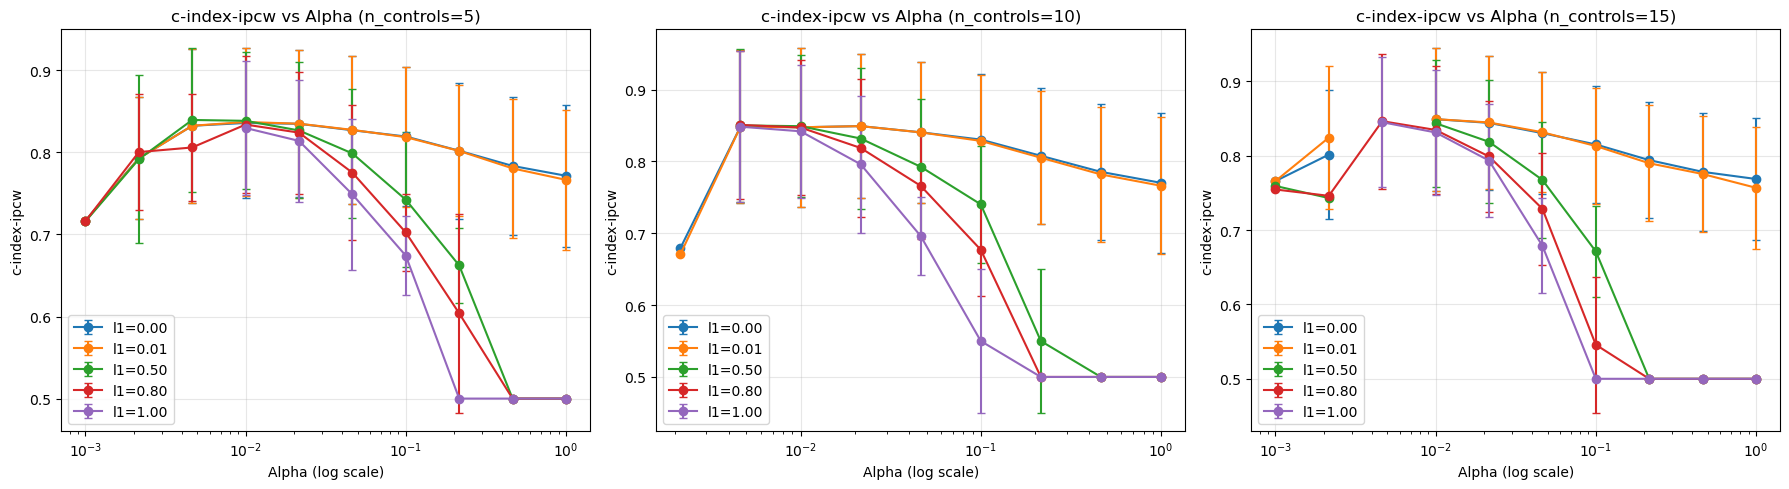

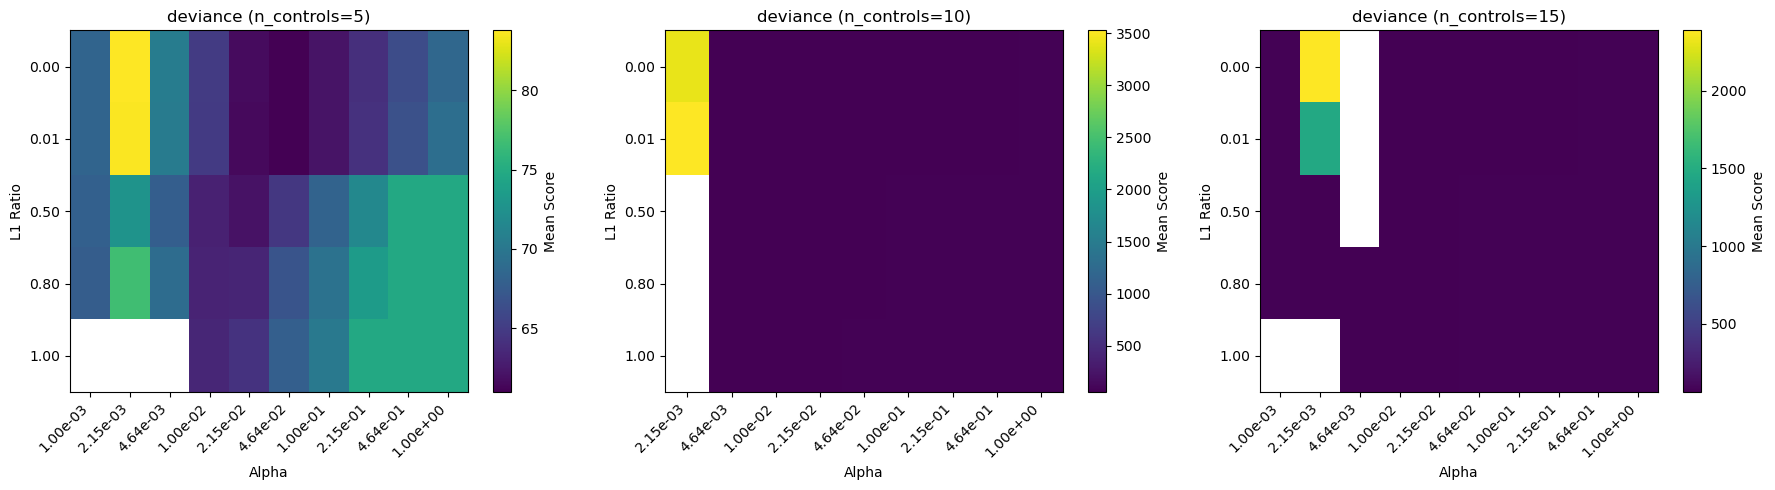

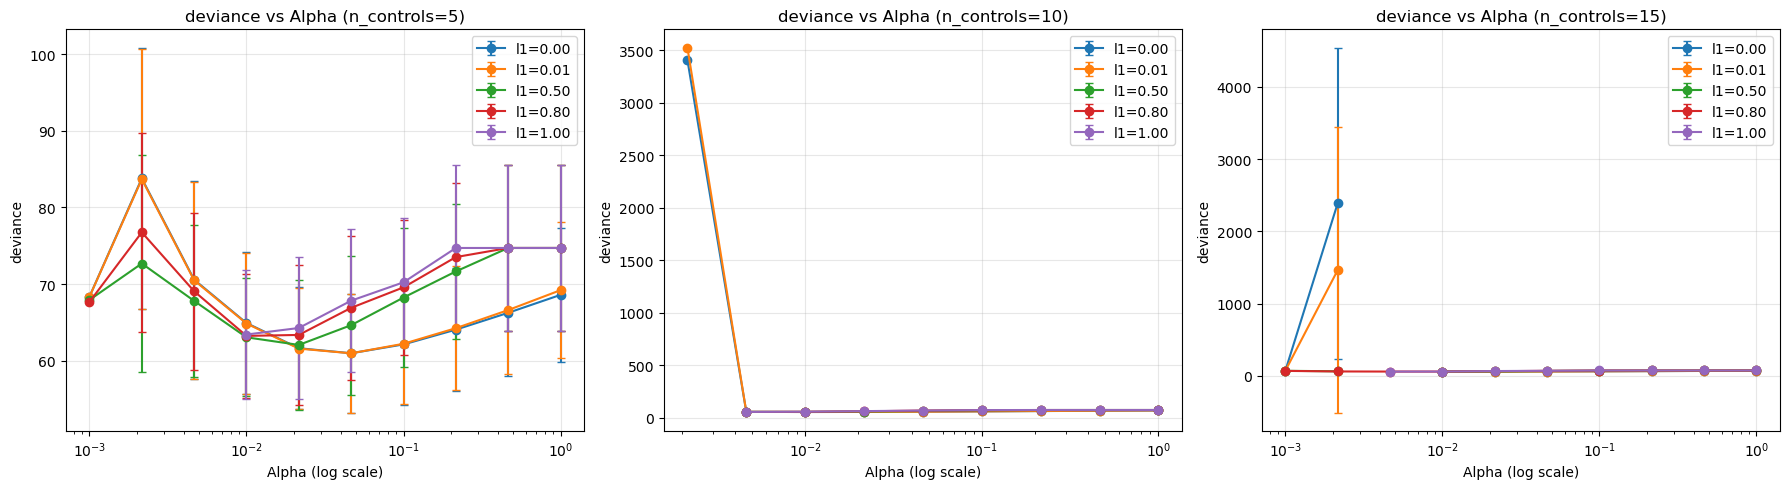

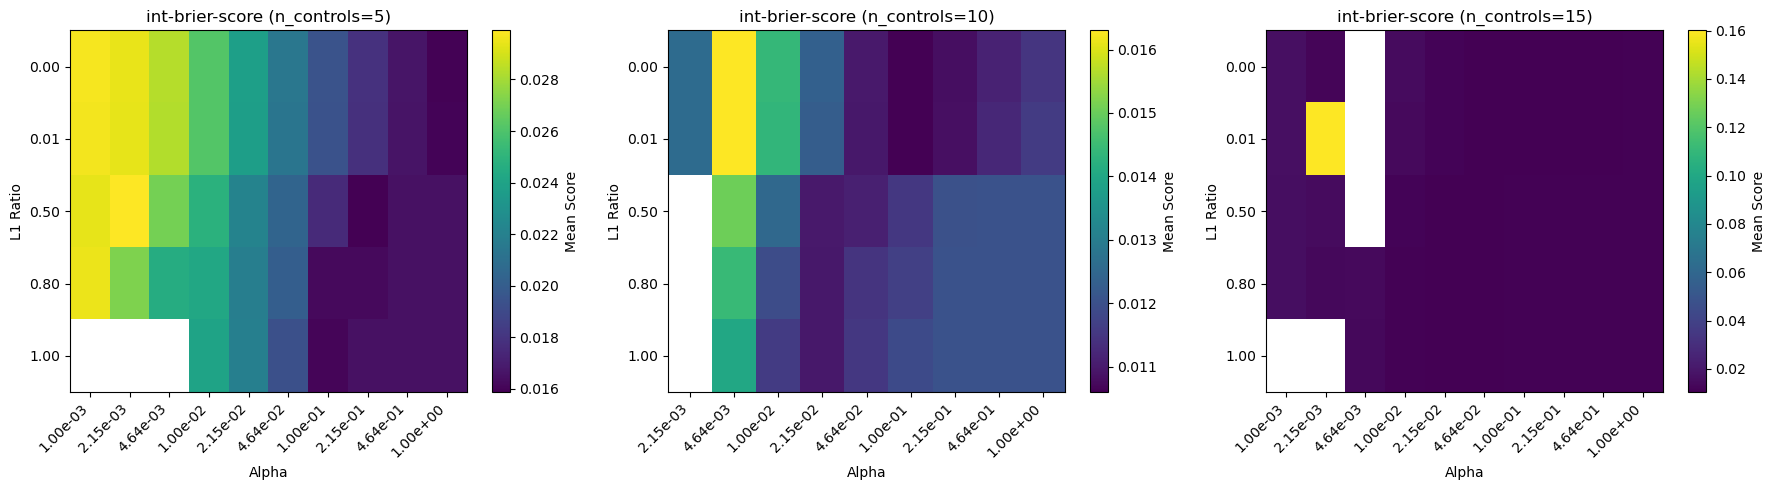

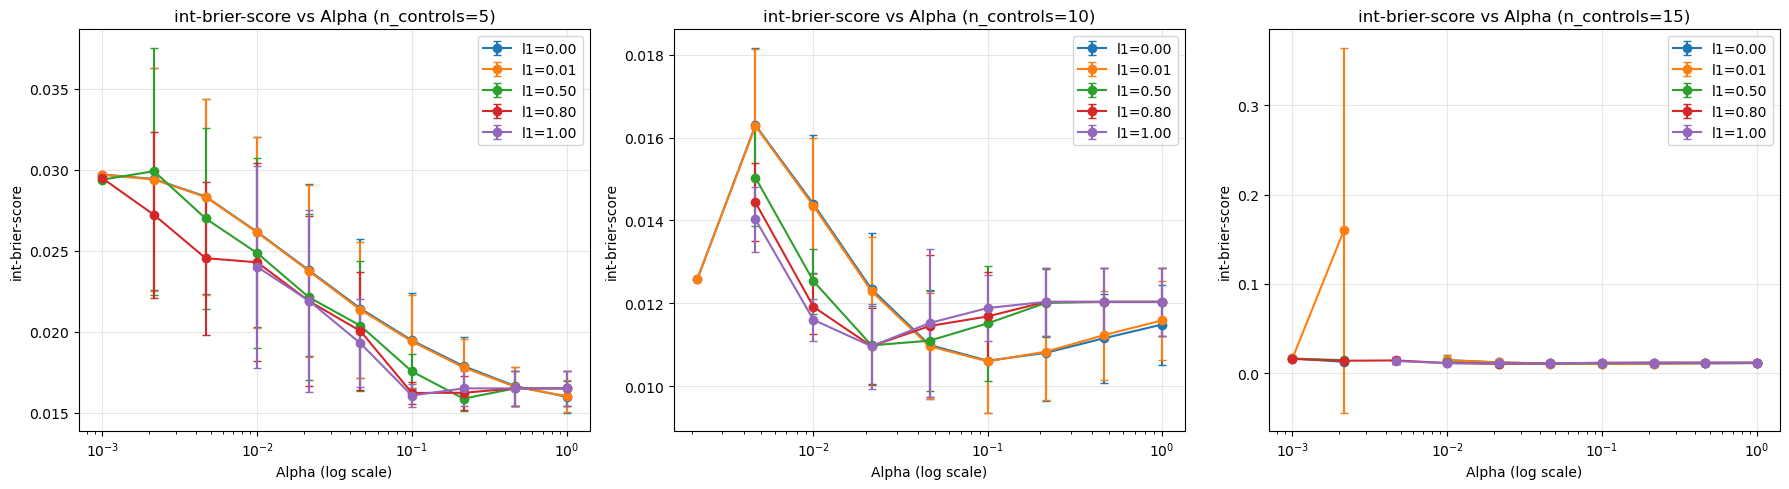

In [16]:
# Access best parameters
print(best_params['c-index-ipcw'])

# Visualize results
plot_grid_search_results(summary_df, metric='c-index')
plot_grid_search_results(summary_df, metric='c-index-ipcw')
plot_grid_search_results(summary_df, metric='deviance')
plot_grid_search_results(summary_df, metric='int-brier-score')

In [ ]:
# Train and evaluate model with subsampling on training set
# Input your chosen hyperparameters below
print("="*80)
print("FINAL MODEL EVALUATION")
print("="*80)

# ============================================================
# INPUT YOUR HYPERPARAMETERS HERE
# ============================================================
n_controls_per_case = 15   # Number of controls per case for subsampling
l1_ratio_best = 1.0        # Lasso regularization
alpha_best = 0.0048329     # Regularization strength
# ============================================================

print(f"\nUsing hyperparameters:")
print(f"  n_controls_per_case: {n_controls_per_case}")
print(f"  l1_ratio: {l1_ratio_best:.4f}")
print(f"  alpha: {alpha_best:.4e}")
    
print(f"\n" + "-"*80)
print("TRAINING WITH SUBSAMPLING")
print("-"*80)

# Apply subsampling to training set
X_train_sub_final, y_train_sub_final, sub_dataset_final = sample_case_control(
    subsampling, 
    event_col='Regional LN recurrence', 
    time_col='Survival days', 
    n_controls_per_case=n_controls_per_case, 
    feature_columns=feature_columns,
    random_state=12
)

print(f"\nTraining data:")
print(f"  Original training samples: {len(x_train)}")
print(f"  Subsampled training samples: {len(X_train_sub_final)}")
print(f"  Events in subsampled training: {y_train_sub_final['event'].sum()}")
print(f"  Test samples: {len(x_test)}")
print(f"  Events in test data: {y_test['event'].sum()}")

# Apply scaling
scaler_final = StandardScaler()
X_train_scaled_final = scaler_final.fit_transform(X_train_sub_final)
X_test_scaled_final = scaler_final.transform(x_test)

print(f"\nTraining Cox model with subsampled training set...")

# Train the model on subsampled training data
model_final = CoxnetSurvivalAnalysis(
    alphas=[alpha_best], 
    l1_ratio=l1_ratio_best, 
    fit_baseline_model=True,
    max_iter=200000
)
model_final.fit(X_train_scaled_final, y_train_sub_final)

print(f"Model trained successfully!")
print(f"Number of selected features: {np.sum(model_final.coef_.flatten() != 0)}")
    
print(f"\n" + "-"*80)
print("TEST SET EVALUATION")
print("-"*80)

# Predict on test set
predicted_risk_final = model_final.predict(X_test_scaled_final)

# Calculate all metrics
# 1. C-Index
test_cindex_final = concordance_index_censored(
    y_test['event'], 
    y_test['time'], 
    predicted_risk_final
)[0]

# 2. C-Index IPCW
max_time_final = min(y_train_sub_final['time'].max(), y_test['time'].max()) * 0.9
test_cindex_ipcw_final = concordance_index_ipcw(
    y_train_sub_final, 
    y_test, 
    predicted_risk_final, 
    tau=max_time_final
)[0]

# 3. Integrated Brier Score
surv_funcs_final = model_final.predict_survival_function(X_test_scaled_final)
times_brier = np.array([2*365, 5*365, 10*365])
times_brier = times_brier[times_brier <= max_time_final]

if len(times_brier) > 0:
    predicted_survival_probs_final = np.asarray(
        [[fn(t) for t in times_brier] for fn in surv_funcs_final]
    )
    test_brier_final = integrated_brier_score(
        y_train_sub_final, 
        y_test, 
        predicted_survival_probs_final, 
        times_brier
    )
else:
    test_brier_final = np.nan

# 4. Individual Brier scores at specific time points
brier_2yr = np.nan
brier_5yr = np.nan
brier_10yr = np.nan

if 2*365 in times_brier:
    idx_2yr = np.where(times_brier == 2*365)[0][0]
    from sksurv.metrics import brier_score
    brier_2yr = brier_score(y_train_sub_final, y_test, predicted_survival_probs_final[:, idx_2yr], times_brier[idx_2yr])[1][0]

if 5*365 in times_brier:
    idx_5yr = np.where(times_brier == 5*365)[0][0]
    brier_5yr = brier_score(y_train_sub_final, y_test, predicted_survival_probs_final[:, idx_5yr], times_brier[idx_5yr])[1][0]

if 10*365 in times_brier:
    idx_10yr = np.where(times_brier == 10*365)[0][0]
    brier_10yr = brier_score(y_train_sub_final, y_test, predicted_survival_probs_final[:, idx_10yr], times_brier[idx_10yr])[1][0]

print(f"\nTest Set Performance Metrics:")
print(f"  C-Index:                    {test_cindex_final:.4f}")
print(f"  C-Index IPCW:               {test_cindex_ipcw_final:.4f}")
print(f"  Integrated Brier Score:     {test_brier_final:.4f}")
print(f"  Brier Score @ 2 years:      {brier_2yr:.4f}" if not np.isnan(brier_2yr) else "  Brier Score @ 2 years:      N/A")
print(f"  Brier Score @ 5 years:      {brier_5yr:.4f}" if not np.isnan(brier_5yr) else "  Brier Score @ 5 years:      N/A")
print(f"  Brier Score @ 10 years:     {brier_10yr:.4f}" if not np.isnan(brier_10yr) else "  Brier Score @ 10 years:     N/A")

# Display selected features
coefs = model_final.coef_.flatten()
non_zero_mask = coefs != 0
selected_features = np.array(feature_columns)[non_zero_mask]
selected_coefs = coefs[non_zero_mask]

print(f"\n" + "-"*80)
print(f"SELECTED FEATURES ({len(selected_features)} features)")
print("-"*80)

feature_coef_df = pd.DataFrame({
    'Feature': selected_features,
    'Coefficient': selected_coefs
})
feature_coef_df = feature_coef_df.sort_values('Coefficient', key=abs, ascending=False)
print(feature_coef_df.to_string(index=False))

# Store results for later use
final_model_results = {
    'model': model_final,
    'scaler': scaler_final,
    'hyperparameters': {
        'n_controls_per_case': n_controls_per_case,
        'l1_ratio': l1_ratio_best,
        'alpha': alpha_best
    },
    'test_metrics': {
        'c-index': test_cindex_final,
        'c-index-ipcw': test_cindex_ipcw_final,
        'int-brier-score': test_brier_final,
        'brier_2yr': brier_2yr,
        'brier_5yr': brier_5yr,
        'brier_10yr': brier_10yr
    }
}

print(f"\n✅ Results stored in 'final_model_results' variable")
print("\n" + "="*80)

In [ ]:
# Manually build best_params dictionary (without needing to run grid search)
# Replace these values with your actual best hyperparameters from grid search

best_params = {
    'c-index': {
        'n_controls': 15,
        'l1_ratio': 1.0,
        'alpha': 0.0078476,
        'mean': 0.7500,  # Replace with actual CV mean
        'std': 0.0500    # Replace with actual CV std
    },
    'c-index-ipcw': {
        'n_controls': 10,
        'l1_ratio': 1.0,
        'alpha': 0.0062102,
        'mean': 0.7200,  # Replace with actual CV mean
        'std': 0.0600    # Replace with actual CV std
    },
    'brier_2yr': {
        'n_controls': 15,
        'l1_ratio': 1.0,
        'alpha': 0.0048329,
        'mean': 0.1500,  # Replace with actual CV mean (lower is better)
        'std': 0.0200    # Replace with actual CV std
    },
    'brier_5yr': {
        'n_controls': 15,
        'l1_ratio': 1.0,
        'alpha': 0.0048329,
        'mean': 0.1800,  # Replace with actual CV mean (lower is better)
        'std': 0.0250    # Replace with actual CV std
    },
    'brier_10yr': {
        'n_controls': 15,
        'l1_ratio': 1.0,
        'alpha': 0.0048329,
        'mean': 0.2000,  # Replace with actual CV mean (lower is better)
        'std': 0.0300    # Replace with actual CV std
    }
}

print("best_params dictionary created!")
print("\n⚠️  NOTE: Update the mean and std values with your actual CV results from grid search")
print("Current values are placeholders for the structure.\n")
print(best_params)

In [ ]:
# Train and evaluate model using best c-index-ipcw hyperparameters on full train/test split
# IMPORTANT: Using same subsampling approach as in CV to maintain consistency
print("="*80)
print("FINAL MODEL EVALUATION WITH BEST C-INDEX-IPCW HYPERPARAMETERS")
print("="*80)

if 'c-index-ipcw' in best_params:
    # Get best hyperparameters
    best_ipcw_params = best_params['c-index-ipcw']
    n_controls_best = best_ipcw_params['n_controls']
    l1_ratio_best = best_ipcw_params['l1_ratio']
    alpha_best = best_ipcw_params['alpha']
    
    print(f"\nBest c-index-ipcw hyperparameters:")
    print(f"  n_controls_per_case: {n_controls_best}")
    print(f"  l1_ratio: {l1_ratio_best:.4f}")
    print(f"  alpha: {alpha_best:.4e}")
    print(f"  CV Mean: {best_ipcw_params['mean']:.4f}")
    print(f"  CV Std:  {best_ipcw_params['std']:.4f}")
    
    print(f"\n" + "-"*80)
    print("TRAINING ON FULL TRAINING SET WITH SUBSAMPLING")
    print("-"*80)
    print("(Maintaining consistency with CV approach)")
    
    # Apply subsampling to full training set (same as in CV)
    X_train_sub_final, y_train_sub_final, sub_dataset_final = sample_case_control(
        subsampling, 
        event_col='Regional LN recurrence', 
        time_col='Survival days', 
        n_controls_per_case=n_controls_best, 
        feature_columns=feature_columns,
        random_state=12
    )
    
    print(f"\nTraining data after subsampling:")
    print(f"  Original training samples: {len(x_train)}")
    print(f"  Subsampled training samples: {len(X_train_sub_final)}")
    print(f"  Events in subsampled data: {y_train_sub_final['event'].sum()}")
    print(f"  Censored in subsampled data: {(~y_train_sub_final['event']).sum()}")
    print(f"  Test samples: {len(x_test)}")
    print(f"  Events in test data: {y_test['event'].sum()}")
    
    # Apply scaling
    scaler_final = StandardScaler()
    X_train_sub_scaled_final = scaler_final.fit_transform(X_train_sub_final)
    X_test_scaled_final = scaler_final.transform(x_test)
    
    print(f"\nTraining model with Cox regression...")
    
    # Train the model on subsampled training data
    model_final = CoxnetSurvivalAnalysis(
        alphas=[alpha_best], 
        l1_ratio=l1_ratio_best, 
        fit_baseline_model=True,
        max_iter=200000
    )
    model_final.fit(X_train_sub_scaled_final, y_train_sub_final)
    
    print(f"Model trained successfully!")
    print(f"Number of selected features: {np.sum(model_final.coef_.flatten() != 0)}")
    
    print(f"\n" + "-"*80)
    print("TEST SET EVALUATION")
    print("-"*80)
    
    # Predict on test set
    predicted_risk_final = model_final.predict(X_test_scaled_final)
    
    # Calculate all metrics
    # 1. C-Index
    test_cindex_final = concordance_index_censored(
        y_test['event'], 
        y_test['time'], 
        predicted_risk_final
    )[0]
    
    # 2. C-Index IPCW
    max_time_final = min(y_train_sub_final['time'].max(), y_test['time'].max()) * 0.9
    test_cindex_ipcw_final = concordance_index_ipcw(
        y_train_sub_final, 
        y_test, 
        predicted_risk_final, 
        tau=max_time_final
    )[0]
    
    # 3. Integrated Brier Score
    surv_funcs_final = model_final.predict_survival_function(X_test_scaled_final)
    times_brier = np.array([2*365, 5*365, 10*365])
    times_brier = times_brier[times_brier <= max_time_final]
    
    if len(times_brier) > 0:
        predicted_survival_probs_final = np.asarray(
            [[fn(t) for t in times_brier] for fn in surv_funcs_final]
        )
        test_brier_final = integrated_brier_score(
            y_train_sub_final, 
            y_test, 
            predicted_survival_probs_final, 
            times_brier
        )
    else:
        test_brier_final = np.nan
    
    # 4. Individual Brier scores at specific time points
    brier_2yr = np.nan
    brier_5yr = np.nan
    brier_10yr = np.nan
    
    if 2*365 in times_brier:
        idx_2yr = np.where(times_brier == 2*365)[0][0]
        from sksurv.metrics import brier_score
        brier_2yr = brier_score(y_train_sub_final, y_test, predicted_survival_probs_final[:, idx_2yr], times_brier[idx_2yr])[1][0]
    
    if 5*365 in times_brier:
        idx_5yr = np.where(times_brier == 5*365)[0][0]
        brier_5yr = brier_score(y_train_sub_final, y_test, predicted_survival_probs_final[:, idx_5yr], times_brier[idx_5yr])[1][0]
    
    if 10*365 in times_brier:
        idx_10yr = np.where(times_brier == 10*365)[0][0]
        brier_10yr = brier_score(y_train_sub_final, y_test, predicted_survival_probs_final[:, idx_10yr], times_brier[idx_10yr])[1][0]
    
    print(f"\nTest Set Performance Metrics:")
    print(f"  C-Index:                    {test_cindex_final:.4f}")
    print(f"  C-Index IPCW:               {test_cindex_ipcw_final:.4f}")
    print(f"  Integrated Brier Score:     {test_brier_final:.4f}")
    print(f"  Brier Score @ 2 years:      {brier_2yr:.4f}" if not np.isnan(brier_2yr) else "  Brier Score @ 2 years:      N/A")
    print(f"  Brier Score @ 5 years:      {brier_5yr:.4f}" if not np.isnan(brier_5yr) else "  Brier Score @ 5 years:      N/A")
    print(f"  Brier Score @ 10 years:     {brier_10yr:.4f}" if not np.isnan(brier_10yr) else "  Brier Score @ 10 years:     N/A")
    
    print(f"\n" + "-"*80)
    print("COMPARISON: CV vs TEST PERFORMANCE")
    print("-"*80)
    
    print(f"\nC-Index IPCW (optimized metric):")
    print(f"  CV Performance:   {best_ipcw_params['mean']:.4f} ± {best_ipcw_params['std']:.4f}")
    print(f"  Test Performance: {test_cindex_ipcw_final:.4f}")
    print(f"  Difference:       {test_cindex_ipcw_final - best_ipcw_params['mean']:+.4f}")
    
    
    print(f"  Test Performance: {test_cindex_final:.4f}")
    
    
else:
    print("\n⚠️  No valid c-index-ipcw configuration found!")

print("\n" + "="*80)